In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS, summarize)
from ISLP import confusion_table
from ISLP.models import contrast
from sklearn.discriminant_analysis import \
(LinearDiscriminantAnalysis as LDA,
QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression


========================= Weekly.shape ==============================
(1089, 9)
========================= Weekly.info() ==============================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1089 entries, 0 to 1088
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   Year       1089 non-null   int64   
 1   Lag1       1089 non-null   float64 
 2   Lag2       1089 non-null   float64 
 3   Lag3       1089 non-null   float64 
 4   Lag4       1089 non-null   float64 
 5   Lag5       1089 non-null   float64 
 6   Volume     1089 non-null   float64 
 7   Today      1089 non-null   float64 
 8   Direction  1089 non-null   category
dtypes: category(1), float64(7), int64(1)
memory usage: 69.4 KB
========================Weekly.columns===============================
Index(['Year', 'Lag1', 'Lag2', 'Lag3', 'Lag4', 'Lag5', 'Volume', 'Today',
       'Direction'],
      dtype='object')
=======================Weekly.describe()=

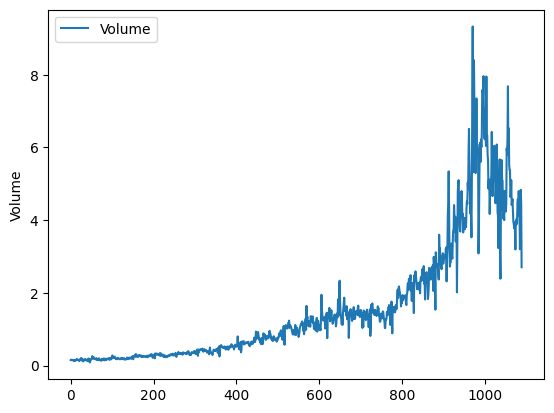

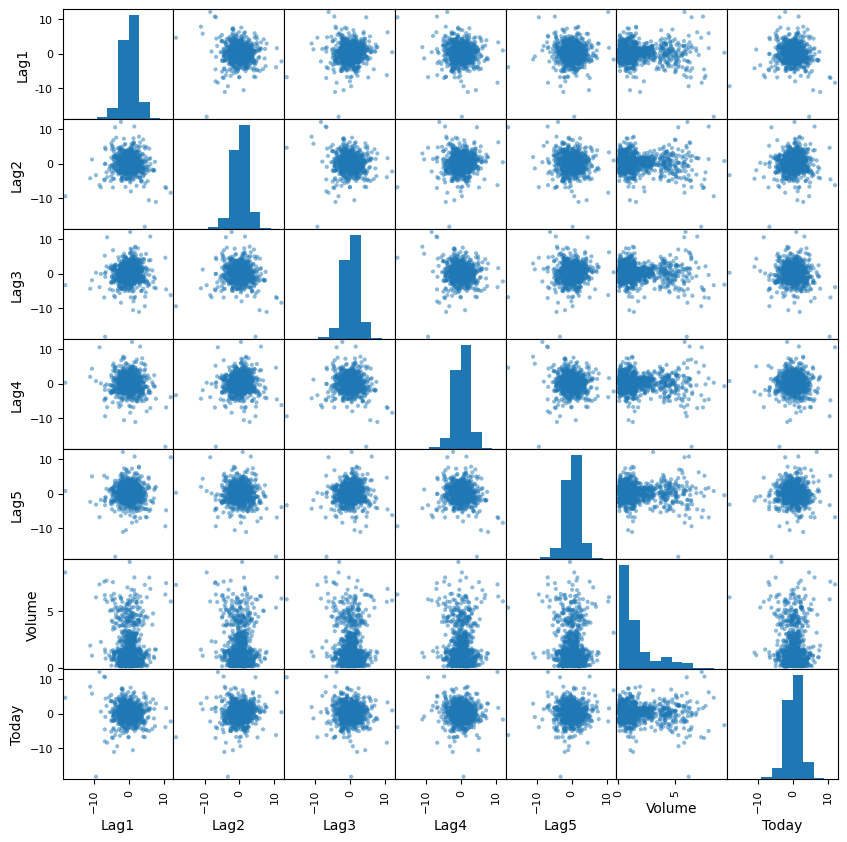

In [40]:
Weekly = load_data('Weekly')
print("========================= Weekly.shape ==============================")
print(Weekly.shape)
print("========================= Weekly.info() ==============================")
Weekly.info()
print("========================Weekly.columns===============================")
print(Weekly.columns)
print("=======================Weekly.describe()=============================")
print(Weekly.describe())
print("======================Weekly['Direction'].value_counts()=============================")
print(Weekly["Direction"].value_counts())
print("=======================================================")
print(Weekly["Direction"].value_counts(normalize=True))
print("=======================================================")
print(Weekly.corr(numeric_only=True))
print("=======================================================")
# Weekly.plot(x="Year", y="Volume")
Weekly.plot(y="Volume")
plt.ylabel("Volume")
plt.show()
print("=======================================================")

pd.plotting.scatter_matrix(
    Weekly[["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume", "Today"]],
    figsize=(10, 10)
)

plt.show()

In [29]:
allvars = Weekly.columns.drop(['Today', 'Direction', 'Year'])
design = MS(allvars)
X = design.fit_transform(Weekly)
y = Weekly.Direction == 'Up'
glm = sm.GLM(y,
X,
family=sm.families.Binomial())
results = glm.fit()
summarize(results)

,coef,std err,z,P>|z|
intercept,0.2669,0.086,3.106,0.002
Lag1,-0.0413,0.026,-1.563,0.118
Lag2,0.0584,0.027,2.175,0.030
Lag3,-0.0161,0.027,-0.602,0.547
Lag4,-0.0278,0.026,-1.050,0.294
Lag5,-0.0145,0.026,-0.549,0.583
Volume,-0.0227,0.037,-0.616,0.538


In [42]:
probs = results.predict()
labels = np.array(['Down']*1089)
labels[probs >0.5] = "Up"
confusion_table(labels, Weekly.Direction)

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


In [ ]:
# Training / test split
train = Weekly.Year <= 2008
Weekly_train = Weekly.loc[train]
Weekly_test = Weekly.loc[~train]

# Fit logistic regression using Lag2 only
design = MS(['Lag2'])
X_train = design.fit_transform(Weekly_train)
y_train = Weekly_train.Direction == 'Up'

glm = sm.GLM(
    y_train,
    X_train,
    family=sm.families.Binomial()
)
results_train = glm.fit()
summarize(results_train)

,coef,std err,z,P>|z|
intercept,0.2033,0.064,3.162,0.002
Lag2,0.0581,0.029,2.024,0.043


In [58]:
# Predict on TEST data (2009-2010)
X_test = design.transform(Weekly_test)
probs_test = results_train.predict(X_test)

labels_test = np.array(['Down'] * len(Weekly_test))
labels_test[probs_test > 0.5] = 'Up'

confusion_table(labels_test, Weekly_test.Direction)

logistic_acc = np.mean(labels_test == Weekly_test.Direction)

In [65]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from ISLP import confusion_table

# Common train/test split: 1990-2008 vs. 2009-2010
train = Weekly.Year <= 2008
Weekly_train = Weekly.loc[train]
Weekly_test = Weekly.loc[~train]

X_train = Weekly_train[['Lag2']]
X_test = Weekly_test[['Lag2']]

y_train = Weekly_train['Direction']
y_test = Weekly_test['Direction']

In [66]:
lda = LDA()
lda.fit(X_train, y_train)
lda_pred = lda.predict(X_test)
confusion_table(lda_pred, y_test)
lda_acc = np.mean(lda_pred == y_test)

print("===== LDA Summary =====")
print("Classes:", lda.classes_)
print("Class priors:", lda.priors_)
print("Class means:", lda.means_)
print("Coefficients:", lda.coef_)
print("Intercept:", lda.intercept_)

print("\n===== Confusion Matrix =====")
display(confusion_table(lda_pred, y_test))

print("Accuracy:", lda_acc)

qda = QDA()
qda.fit(X_train, y_train)
qda_pred = qda.predict(X_test)
confusion_table(qda_pred, y_test)
qda_acc = np.mean(qda_pred == y_test)

print("===== QDA Summary =====")
print("Classes:", qda.classes_)
print("Class priors:", qda.priors_)
print("Class means:", qda.means_)

print("\n===== Confusion Matrix =====")
display(confusion_table(qda_pred, y_test))

print("Accuracy:", qda_acc)

knn1 = KNeighborsClassifier(n_neighbors=1)
knn1.fit(X_train, y_train)
knn1_pred = knn1.predict(X_test)
confusion_table(knn1_pred, y_test)
knn1_acc = np.mean(knn1_pred == y_test)

print("===== KNN Summary =====")
print("Number of neighbors:", knn1.n_neighbors)
print("Number of training observations:", len(X_train))

print("\n===== Confusion Matrix =====")
display(confusion_table(knn1_pred, y_test))

print("Accuracy:", knn1_acc)

nb = GaussianNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)

confusion_table(nb_pred, y_test)
nb_acc = np.mean(nb_pred == y_test)

print("===== Naive Bayes Summary =====")
print("Classes:", nb.classes_)
print("Class priors:", nb.class_prior_)
print("Class means:", nb.theta_)
print("Class variances:", nb.var_)

print("\n===== Confusion Matrix =====")
display(confusion_table(nb_pred, y_test))

print("Accuracy:", nb_acc)


===== LDA Summary =====
Classes: ['Down' 'Up']
Class priors: [0.44771574 0.55228426]
Class means: [[-0.03568254]
 [ 0.26036581]]
Coefficients: [[0.05768451]]
Intercept: [0.203424]

===== Confusion Matrix =====


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


Accuracy: 0.625
===== QDA Summary =====
Classes: ['Down' 'Up']
Class priors: [0.44771574 0.55228426]
Class means: [[-0.03568254]
 [ 0.26036581]]

===== Confusion Matrix =====


Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


Accuracy: 0.5865384615384616
===== KNN Summary =====
Number of neighbors: 1
Number of training observations: 985

===== Confusion Matrix =====


Truth,Down,Up
Predicted,,
Down,21,30
Up,22,31


Accuracy: 0.5
===== Naive Bayes Summary =====
Classes: ['Down' 'Up']
Class priors: [0.44771574 0.55228426]
Class means: [[-0.03568254]
 [ 0.26036581]]
Class variances: [[4.82684748]
 [5.3608662 ]]

===== Confusion Matrix =====


Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


Accuracy: 0.5865384615384616


In [68]:
print("Logistic :", logistic_acc)
print("LDA      :", lda_acc)
print("QDA      :", qda_acc)
print("KNN (K=1):", knn1_acc)
print("Naive Bayes:", nb_acc)

Logistic : 0.625
LDA      : 0.625
QDA      : 0.5865384615384616
KNN (K=1): 0.5
Naive Bayes: 0.5865384615384616


In [69]:
# Additional features
Weekly = Weekly.copy()
Weekly["Lag2_sq"] = Weekly["Lag2"]**2
Weekly["Lag1_Lag2"] = Weekly["Lag1"] * Weekly["Lag2"]

# Train / test split
train = Weekly.Year <= 2008
train_df = Weekly.loc[train]
test_df  = Weekly.loc[~train]

# Predictor combinations
predictor_sets = {
    "Lag2": ["Lag2"],
    "Lag1+Lag2": ["Lag1", "Lag2"],
    "Lag2+Lag3": ["Lag2", "Lag3"],
    "All Lags": ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5"],
    "All+Volume": ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"],
    "Lag2+Lag2^2": ["Lag2", "Lag2_sq"],
    "Lag1+Lag2+Interaction": ["Lag1", "Lag2", "Lag1_Lag2"]
}

models = {
    "Logistic": LogisticRegression(max_iter=1000),
    "LDA": LDA(),
    "QDA": QDA(),
    "Naive Bayes": GaussianNB()
}

results = []

# Logistic, LDA, QDA, Naive Bayes
for p_name, cols in predictor_sets.items():
    X_train, X_test = train_df[cols], test_df[cols]
    y_train, y_test = train_df.Direction, test_df.Direction

    for m_name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        results.append([m_name, p_name, np.mean(pred == y_test), pred])

# KNN: try several K values
for p_name, cols in predictor_sets.items():
    X_train, X_test = train_df[cols], test_df[cols]

    for k in [1, 3, 5, 10, 20]:
        model = KNeighborsClassifier(n_neighbors=k)
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        results.append([f"KNN (K={k})", p_name,
                        np.mean(pred == y_test), pred])

# Compare results
results_df = pd.DataFrame(
    results, columns=["Method", "Predictors", "Accuracy", "Prediction"]
).sort_values("Accuracy", ascending=False)

display(results_df[["Method", "Predictors", "Accuracy"]].head(15))

# Best model
best = results_df.iloc[0]

print("===== Best Model =====")
print("Method:", best["Method"])
print("Predictors:", best["Predictors"])
print("Accuracy:", best["Accuracy"])

print("\nConfusion Matrix:")
display(confusion_table(best["Prediction"], y_test))

/Users/danbi-kim/Desktop/Github_Repositories/Basic_Statistics_Examples/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/danbi-kim/Desktop/Github_Repositories/Basic_Statistics_Examples/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/danbi-kim/Desktop/Github_Repositories/Basic_Statistics_Examples/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/danbi-kim/Desktop/Github_Repositories/Basic_Statistics_Examples/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in m

,Method,Predictors,Accuracy
0,Logistic,Lag2,0.625000
8,Logistic,Lag2+Lag3,0.625000
22,QDA,Lag2+Lag2^2,0.625000
1,LDA,Lag2,0.625000
20,Logistic,Lag2+Lag2^2,0.625000
9,LDA,Lag2+Lag3,0.625000
21,LDA,Lag2+Lag2^2,0.615385
60,KNN (K=5),Lag1+Lag2+Interaction,0.615385
10,QDA,Lag2+Lag3,0.605769
32,KNN (K=20),Lag2,0.596154


===== Best Model =====
Method: Logistic
Predictors: Lag2
Accuracy: 0.625

Confusion Matrix:


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


In [70]:
Auto = load_data('Auto')

mpg_median = Auto['mpg'].median()

Auto['mpg01'] = (Auto['mpg'] > mpg_median).astype(int)

print("Median mpg:", mpg_median)
print(Auto['mpg01'].value_counts())
Auto.head()

Median mpg: 22.75
mpg01
0    196
1    196
Name: count, dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,mpg01
name,,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1,0
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1,0
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1,0
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1,0
ford torino,17.0,8,302.0,140,3449,10.5,70,1,0


Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'year', 'origin', 'mpg01'],
      dtype='object')
             mpg  cylinders  displacement  horsepower       weight  \
mpg01                                                                
0      16.921939   6.765306    273.158163  130.112245  3620.403061   
1      29.969898   4.178571    115.665816   78.826531  2334.765306   

       acceleration       year    origin  
mpg01                                     
0         14.585714  74.397959  1.163265  
1         16.496939  77.561224  1.989796  


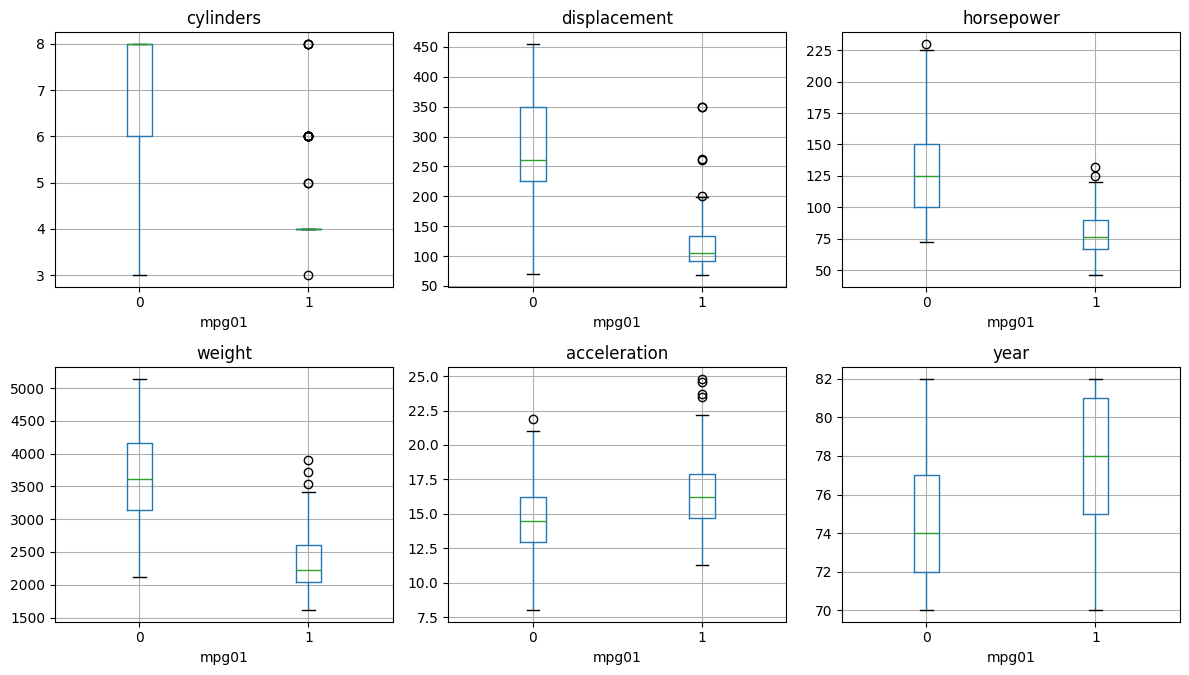

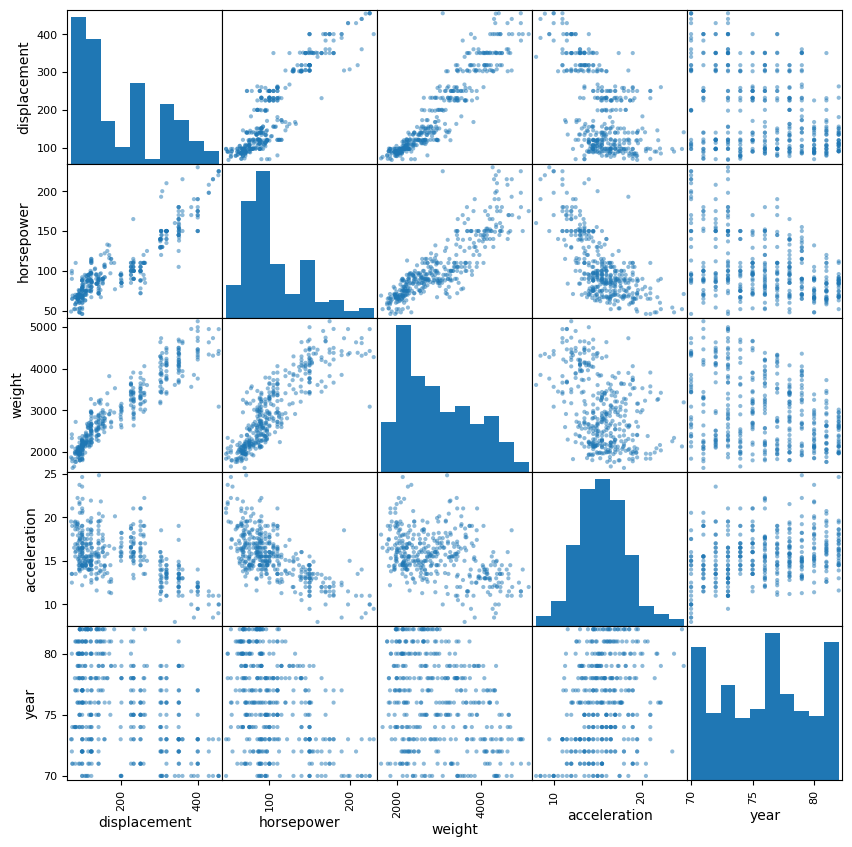

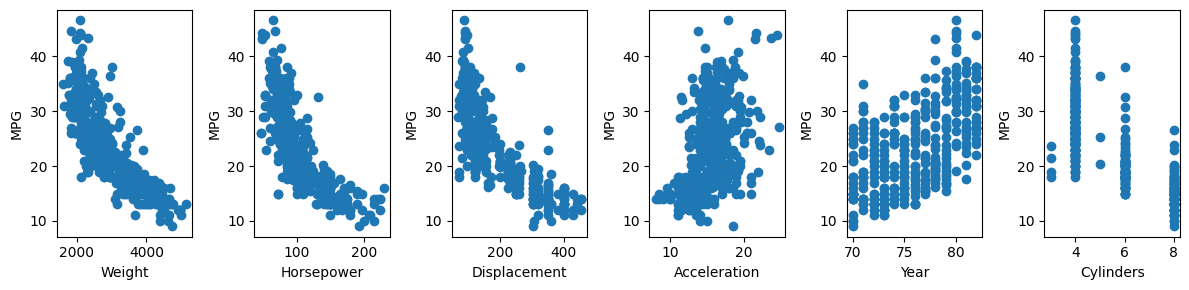

In [83]:
print(Auto.columns)
print(Auto.groupby('mpg01').mean(numeric_only=True))

features = [
    'cylinders', 'displacement', 'horsepower',
    'weight', 'acceleration', 'year'
]

# 1. Boxplots
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, col in zip(axes.ravel(), features):
    Auto.boxplot(column=col, by='mpg01', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('mpg01')

plt.suptitle('')
plt.tight_layout()
plt.show()

# 2. Scatter matrix
pd.plotting.scatter_matrix(
    Auto[['displacement', 'horsepower', 'weight',
          'acceleration', 'year']],
    figsize=(10, 10),
    diagonal='hist'
)
plt.show()

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

axes[0].scatter(Auto['weight'], Auto['mpg'])
axes[0].set_xlabel('Weight')
axes[0].set_ylabel('MPG')

axes[1].scatter(Auto['horsepower'], Auto['mpg'])
axes[1].set_xlabel('Horsepower')
axes[1].set_ylabel('MPG')

axes[2].scatter(Auto['displacement'], Auto['mpg'])
axes[2].set_xlabel('Displacement')
axes[2].set_ylabel('MPG')

axes[3].scatter(Auto['acceleration'], Auto['mpg'])
axes[3].set_xlabel('Acceleration')
axes[3].set_ylabel('MPG')

axes[4].scatter(Auto['year'], Auto['mpg'])
axes[4].set_xlabel('Year')
axes[4].set_ylabel('MPG')

axes[5].scatter(Auto['cylinders'], Auto['mpg'])
axes[5].set_xlabel('Cylinders')
axes[5].set_ylabel('MPG')

plt.tight_layout()
plt.show()


In [84]:
from sklearn.model_selection import train_test_split

predictors = ['cylinders', 'displacement', 'horsepower', 'weight']

X = Auto[predictors]
y = Auto['mpg01']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=1,
    stratify=y
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 274
Test observations: 118


In [85]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

models = {
    "LDA": LDA(),
    "QDA": QDA(),
    "Logistic": LogisticRegression(max_iter=1000),
    "Naive Bayes": GaussianNB()
}

# (d)-(g)
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    error = np.mean(pred != y_test)

    print(f"\n===== {name} =====")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, pred))
    print(f"Test Error: {error:.4f}")
    print(f"Accuracy:   {1-error:.4f}")


# (h) KNN with several K values
print("\n===== KNN =====")

knn_results = []

for k in [1, 3, 5, 10, 20]:
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    knn.fit(X_train, y_train)
    pred = knn.predict(X_test)

    error = np.mean(pred != y_test)
    knn_results.append((k, error, pred))

    print(f"\nK = {k}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, pred))
    print(f"Test Error: {error:.4f}")
    print(f"Accuracy:   {1-error:.4f}")


# Best K
best_k, best_error, best_pred = min(
    knn_results, key=lambda x: x[1]
)

print("\n===== Best KNN =====")
print("Best K:", best_k)
print(f"Test Error: {best_error:.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, best_pred))


===== LDA =====
Confusion Matrix:
[[51  8]
 [ 4 55]]
Test Error: 0.1017
Accuracy:   0.8983

===== QDA =====
Confusion Matrix:
[[52  7]
 [ 6 53]]
Test Error: 0.1102
Accuracy:   0.8898

===== Logistic =====
Confusion Matrix:
[[51  8]
 [ 5 54]]
Test Error: 0.1102
Accuracy:   0.8898

===== Naive Bayes =====
Confusion Matrix:
[[51  8]
 [ 5 54]]
Test Error: 0.1102
Accuracy:   0.8898

===== KNN =====

K = 1
Confusion Matrix:
[[54  5]
 [ 6 53]]
Test Error: 0.0932
Accuracy:   0.9068

K = 3
Confusion Matrix:
[[52  7]
 [ 6 53]]
Test Error: 0.1102
Accuracy:   0.8898

K = 5
Confusion Matrix:
[[52  7]
 [ 4 55]]
Test Error: 0.0932
Accuracy:   0.9068

K = 10
Confusion Matrix:
[[51  8]
 [ 5 54]]
Test Error: 0.1102
Accuracy:   0.8898

K = 20
Confusion Matrix:
[[51  8]
 [ 5 54]]
Test Error: 0.1102
Accuracy:   0.8898

===== Best KNN =====
Best K: 1
Test Error: 0.0932
Confusion Matrix:
[[54  5]
 [ 6 53]]


/Users/danbi-kim/Desktop/Github_Repositories/Basic_Statistics_Examples/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/danbi-kim/Desktop/Github_Repositories/Basic_Statistics_Examples/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/danbi-kim/Desktop/Github_Repositories/Basic_Statistics_Examples/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
